In [6]:
import Augmentor
import glob
from skimage import io, morphology
import matplotlib.pyplot as plt
from corebreakout.utils.viz_utils import show_images

In [7]:
img_path = '/home/administrator/Dropbox/core_data/segmentation/royal_col_images/'
mask_path = '/home/administrator/Dropbox/core_data/segmentation/royal_col_masks/'

In [8]:
p = Augmentor.Pipeline(img_path)
p.ground_truth(mask_path)

Initialised with 60 image(s) found.
Output directory set to /home/administrator/Dropbox/core_data/segmentation/royal_col_images/output.60 ground truth image(s) found.


In [9]:
p.crop_random(1.0, percentage_area=0.7)
p.rotate(1.0, max_left_rotation=5, max_right_rotation=5)
p.flip_left_right(0.5)
p.flip_top_bottom(0.5)
p.random_color(1.0, min_factor=0.5, max_factor=1.5)
#p.shear(0.5, max_shear_left=10, max_shear_right=10)
p.skew(0.9, magnitude=0.1)

p.gaussian_distortion(0.5, 10, 10, 5, 'bell', 'in')

# brightness causes problems on the masks
#p.random_brightness(0.75, min_factor=0.8, max_factor=1.2)

In [10]:
p.sample(1000)

Processing <PIL.Image.Image image mode=RGB size=1303x375 at 0x7F1A85ED4550>: 100%|██████████| 1000/1000 [04:26<00:00,  3.75 Samples/s]


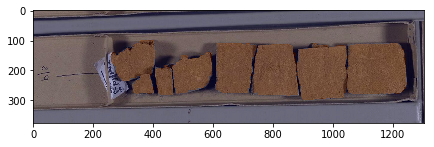

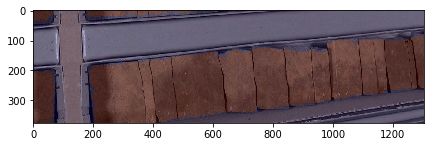

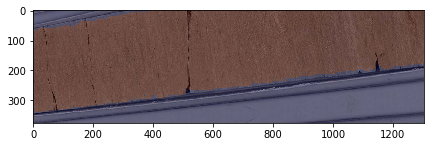

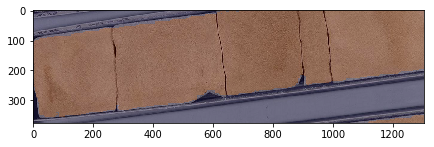

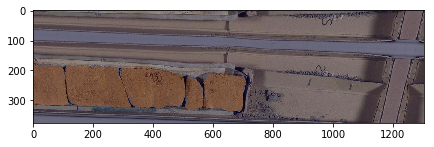

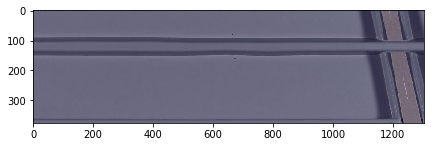

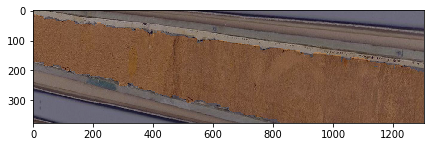

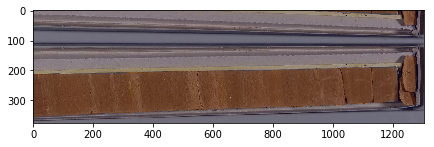

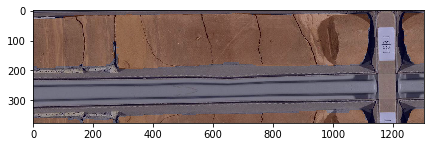

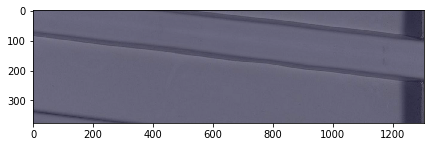

In [11]:
files = sorted(glob.glob(img_path + 'output/*jpeg'))
n = len(files) // 2
fpairs = zip(files[n:], files[:n])

dselem = morphology.selem.disk(3)

ishapes = []
mshapes = []
for i, (img, m) in enumerate(fpairs):
    image = io.imread(img)
    mask = io.imread(m)>0
    if i % 100 == 0:
        plt.figure(figsize=(7,12))
        plt.imshow(image)
        plt.imshow(morphology.binary_dilation(mask,selem=dselem), 'jet', alpha=0.25)
        plt.show()
    ishapes.append(image.shape)
    mshapes.append(mask.shape)

In [12]:
import numpy as np

np.unique(ishapes), np.unique(mshapes)

(array([   3,  375, 1303, 1304]), array([ 375, 1303, 1304]))

## Re-savey Save

In [20]:
from skimage import io, transform
import glob

save_dir = '/home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/'

dselem = morphology.selem.disk(3)

# remove '.jpeg_' --> '_'
def augpath_to_uname(s):
    f = s.split('/')[-1]
    # there's a stupid jpeg in the middle of filename
    f = f.replace('.jpeg_', '_')
    if f.find('original') != -1:
        f = f.replace('original_', '')
        suffix = ''
    else:
        suffix = '_mask'
    return f[f.index('_col_')+1:-5] + suffix + '.jpeg'

files = sorted(glob.glob(img_path + 'output/*jpeg'))
n = len(files) // 2
fpairs = zip(files[n:], files[:n])
for i, m in fpairs:
    img  = io.imread(i)
    mask = morphology.binary_dilation(io.imread(m), selem=dselem)
    # correct for odd shapes 
    img = img[:374,:1302,:]
    mask = mask[:374,:1302]
    io.imsave(save_dir+augpath_to_uname(i), img)
    io.imsave(save_dir+augpath_to_uname(m), mask)

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_0_06f11333-333e-4c71-94de-57058632cd9a_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_0_0b1a4bdc-633d-4850-96ae-b662639312eb_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_0_0dc8c0ab-0659-4a4e-9a61-5314c781eeeb_mask.jpeg is a boolean imag

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_1_c7617eb0-067c-42cf-a7e3-186494307d74_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_1_c76af784-a4bc-4d0b-9f58-9326e8843457_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_1_c9e166b0-d389-4dd9-a65f-553766719312_mask.jpeg is a boolean imag

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_11_1f965cd7-7e56-45a9-af26-39c9486b4cca_mask.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_11_1f965cd7-7e56-45a9-af26-39c9486b4cca_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_11_2ee73655-8a49-41d2-b35f-09708d3968ff_mask.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/ho

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_11_fc657d83-4530-424d-96ac-c003cf8a24f9_mask.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_11_fc657d83-4530-424d-96ac-c003cf8a24f9_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_12_0a33debc-e8e3-4dbf-b57c-6d2d8895816a_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boo

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_13_4015ba4e-248a-44dd-9b19-843d9cd680a7_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_13_436673f3-bc58-4ebc-86ac-867625de079e_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_13_4652dd88-cbca-4870-8bb9-38a54128bf3f_mask.jpeg is a boolean i

...

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_60_0d10a9e8-0c0c-40df-8c2b-7f2bd0c9c35c_mask.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_60_0d10a9e8-0c0c-40df-8c2b-7f2bd0c9c35c_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_60_192dafcc-6c7c-406e-8cda-ba3808049a85_mask.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/ho

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_60_def6e390-6be1-468d-ac3c-b8d9fc01996e_mask.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_60_def6e390-6be1-468d-ac3c-b8d9fc01996e_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_60_f334be3d-8cc5-4bed-b1f4-c94ca80210f5_mask.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/ho

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_61_d7607fff-d505-49c5-b886-17ecc56e7484_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_61_dfdacf9c-4b89-49b9-b213-a3720bf89d22_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_61_ed466c01-6a16-4590-9ce1-751fd15199af_mask.jpeg is a boolean i

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_8_41e72c01-8bf0-49b3-a037-6eb10cd98f9f_mask.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_8_41e72c01-8bf0-49b3-a037-6eb10cd98f9f_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:140: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_8_541af0fb-8832-453f-82f1-5f7e1645b154_mask.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_9_80e26a57-e9cc-47cd-8817-e6542c5a8703_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_9_86ba1c28-f5ec-44f6-af4d-2eb47f60f1c4_mask.jpeg is a boolean image: setting True to 1 and False to 0
  warn('%s is a boolean image: setting True to 1 and False to 0' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:142: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_col_augmented/col_images_col_9_8d0af580-f70f-4170-b921-b1f76863a194_mask.jpeg is a boolean imag